# **IMM - Taller No 4**

# Modelo Exponencial Discreto


El modelo discreto exponencial asume que el cambio en la cantidad entre dos pasos de tiempo consecutivos es proporcional a la cantidad en el paso de tiempo actual. Matemáticamente, un modelo discreto exponencial puede estar representado por la ecuación:


, $$\boxed{P_{n+1}= (\kappa+1) P_{n}}$$ ,

Donde:

   - $P_{n+1}$,​ es la cantidad en el paso de tiempo $n+1$.
   - $P_{n}$, es la cantidad en el paso de tiempo siguiente.
   - $\kappa$, es la tasa de crecimiento o decaimiento.


Este tipo de modelo tiene diversas aplicaciones en varias áreas:

    - Biología: Se puede utilizar para modelar el crecimiento de poblaciones de organismos en ambientes discretos.

    - Economía: Para modelar el crecimiento de inversiones, el aumento de la población laboral, entre otros.

    - Ingeniería: En sistemas de producción, como la producción de bienes en una cadena de montaje, o en la predicción de fallas en sistemas discretos.

    - Tecnología: Por ejemplo, en el modelado de la propagación de virus informáticos en redes discretas de computadoras.

    - Física: Para modelar la desintegración de partículas radiactivas o el decaimiento de una sustancia en un sistema cerrado.

1.

## Ejercicio: crecimiento de una población bacteriana

En un laboratorio se estudia el crecimiento de una población de bacterias cultivadas bajo condiciones controladas. Durante las primeras horas del experimento se supone que los nutrientes y el espacio disponible son suficientes para que la población crezca sin limitaciones importantes.

El número de bacterias se registra al final de cada hora y se obtienen los siguientes datos:

| Tiempo $n$ (horas) | Número de bacterias $P_n$ |
| :----------------: | -------------------------: |
|         0          |                         50 |
|         1          |                         74 |
|         2          |                        111 |
|         3          |                        166 |
|         4          |                        247 |
|         5          |                        368 |
|         6          |                        550 |
|         7          |                        820 |

Se desea construir un modelo matemático sencillo que permita describir la evolución de la población y realizar predicciones para tiempos posteriores.

Supondremos que, durante el período estudiado, la población aumenta aproximadamente en una **proporción constante**. Esto significa que el número de bacterias en una hora puede obtenerse multiplicando la población de la hora anterior por una constante $k$.

De esta manera, proponemos el modelo discreto

$$
P_{n+1}=(\kappa+1)P_n ,
$$

donde $P_n$ representa la población en la hora $n$ y $k$ es el **factor de crecimiento por hora**.

### Preguntas

1. Grafique los datos experimentales $(n,P_n)$ y describa el comportamiento observado en la población.

2.  Utilizando los datos experimentales, estime el valor del parámetro $k$ mediante una regresión lineal.

3. Utilizando el valor estimado de $k$ y la población inicial $P_0$, escriba el modelo discreto que describe el crecimiento de la población.

4.  Utilice el modelo obtenido para calcular los valores de $P_n$ correspondientes a las horas del experimento y compárelos gráficamente con los datos observados.

5. Utilice el modelo para estimar el número de bacterias después de **1 día**.

6. ¿Qué significa el valor obtenido para $k$? Explique.






Solucion

Pregunta 1.

lista de arreglo Tiempo n (horas):[0 1 2 3 4 5 6 7]
lista de arreglo población de bacterias: [ 50  74 111 166 247 368 550 820]


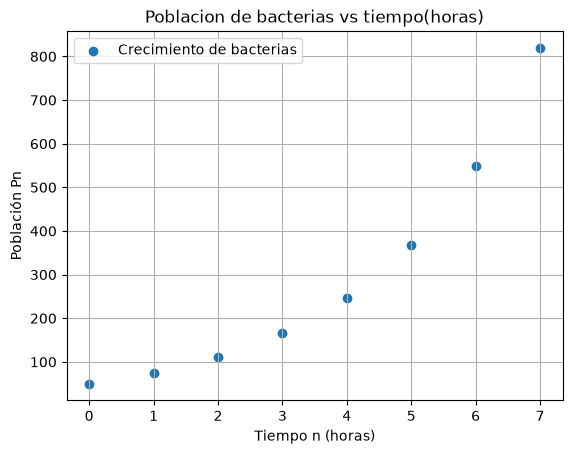

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# a medida que pasa el tiempo (n), la población de bacterias (Pn), no crece sumando una cantidad fija (como una lineal) si no que aumenta cada vez más rapido. la curva en la grafica se dispara hacia arriiba de forma vertical es decir se comporta como una función exponencial.

n_puntos = np.array([0, 1, 2, 3, 4, 5, 6, 7])
Pn_puntos = np.array([50, 74, 111, 166, 247, 368, 550, 820])
print(f'lista de arreglo Tiempo n (horas):{n_puntos}')
print(f'lista de arreglo población de bacterias: {Pn_puntos}')

plt.scatter(n_puntos, Pn_puntos, label = 'Crecimiento de bacterias')
plt.title('Poblacion de bacterias vs tiempo(horas)')
plt.xlabel("Tiempo n (horas)")
plt.ylabel("Población Pn")
plt.legend()
plt.grid()
plt.show()


Pregunta 2. solución profesor


,$$P_{n+1} = (\kappa + 1) P_n$$, 

,$$\frac{P_{n+1}}{P_n} = \kappa + 1$$,


Los resultados pueden organizarse en la siguiente tabla:

| $n$ | $P_n$ | $ P_{n+1} $ | $\frac{P_{n+1}}{P_n}$ |
|---:|---:|-------:|-------:|
| 0 | 50 | 74 | 1.480 |
| 1 | 74 | 111 | 1.500 |
| 2 | 111 | 166 | 1.495 |
| 3 | 166 | 247 | 1.488 |
| 4 | 247 | 368 | 1.490 |
| 5 | 368 | 550 | 1.495 |
| 6 | 550 | 820 | 1.491 |

Observamos que los cocientes son muy cercanos a un valor constante.

cocientes cercanos a un valor constante (P_n + 1/P_n): 
[1.48 1.5  1.5  1.49 1.49 1.49 1.49]
nuestra pendientes es: 0.0006 y nuestro intercepto es: 1.4895

por tanto nuestra constante K + 1 es igual a nuestro intercepto: 
1.4895

nuestra constante despejada k es igual: 
0.4895

Grafica 1. Cocientes (P_n + 1/pn) vs horas


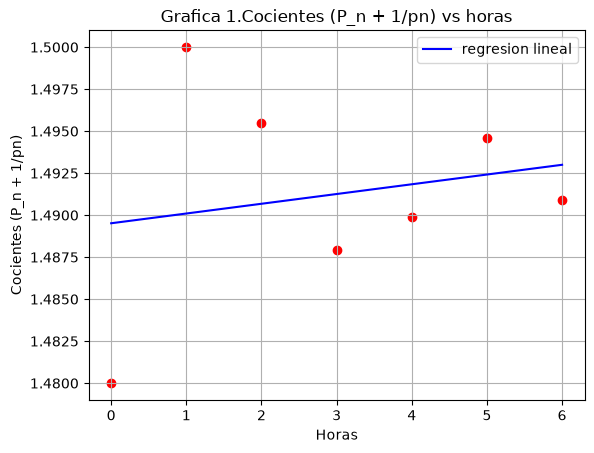

In [35]:
from scipy.stats import linregress 

# Se divide el valor despues con el valor anterior ej. (P_n+1/pn = 74/50)
cociente_n= Pn_puntos[1:]/ Pn_puntos[:-1]
print(f'cocientes cercanos a un valor constante (P_n + 1/P_n): \n{np.round(cociente_n, 2)}') 

# tomamos como eje X n_puntos que son las horas que pasan y eje Y cociente_n que es la division lo cual por cambio de variable es (y)
regresió_lineal = linregress(n_puntos[:-1], cociente_n)

pendiente = regresió_lineal.slope
intercepto = regresió_lineal.intercept

y_regresion = pendiente*n_puntos[:-1] + intercepto

k = intercepto - 1 

print(f'nuestra pendientes es: {np.round(pendiente, 4)} y nuestro intercepto es: {np.round(intercepto, 4)}')
print()
print(f'por tanto nuestra constante K + 1 es igual a nuestro intercepto: \n{np.round(intercepto, 4)}')
print()
print(f'nuestra constante despejada k es igual: \n{np.round(k, 4)}')
print()

print('Grafica 1. Cocientes (P_n + 1/pn) vs horas')
plt.scatter(n_puntos[:-1], cociente_n, color = 'red')
plt.plot(n_puntos[:-1], y_regresion, linestyle = '-', color = 'blue', label ='regresion lineal')
plt.title('Grafica 1.Cocientes (P_n + 1/pn) vs horas')
plt.xlabel('Horas')
plt.ylabel('Cocientes (P_n + 1/pn)')
plt.legend()
plt.grid(True)
plt.show()

Pregunta 2. solución Sebastian

## resolviendo ecuación diferencial: 

,En el minuto 0: $P_0$,

,En el minuto 1: $P_1 = (k+1)P_0$,

,En el minuto 2: $P_2 = (k+1)P_1 = (k+1) \cdot [(k+1)P_0] = (k+1)^2 P_0$,

,En el minuto $n$: $P_n = P_0 (1+k)^n$,

lo anterior es el resultado acumulado despues de n horas.

## cambio de variables. 

,$$P_n = P_0 \cdot (1 + k)^n$$,

,$$\ln(P_n) = \ln\Big( P_0 \cdot (1 + k)^n \Big)$$,

,$$\ln(P_n) = \ln(P_0) + \ln\left((1 + k)^n\right)$$,

,$$\ln(P_n) = \ln(P_0) + n \cdot \ln(1 + k)$$,

,$$\ln(P_n) = \underbrace{\ln(1 + k)}_{m} \cdot \underbrace{n}_{x} + \underbrace{\ln(P_0)}_{b}$$,

## encontrar el parametro k.

,$$m = \ln(1 + k) \quad \rightarrow \quad 1 + k = e^m$$,

,$$k = e^m - 1$$,

Cambio de variable y = 
[3.91 4.3  4.71 5.11 5.51 5.91 6.31 6.71]

Cambio de variable x = 
[0 1 2 3 4 5 6 7]
Ecuación de la recta: 
[3.90915025 4.30918946 4.70922868 5.10926789 5.50930711 5.90934632
 6.30938553 6.70942475]

La pendiente m=ln(1+K) es igual a :0.4

El intercepto b=ln(P_0) es igual a : 3.91

El parametro de K es igual a:0.4919 

el factor de K + 1 e igual a:1.4919 

intercepto de la recta es igual a: 49.8566


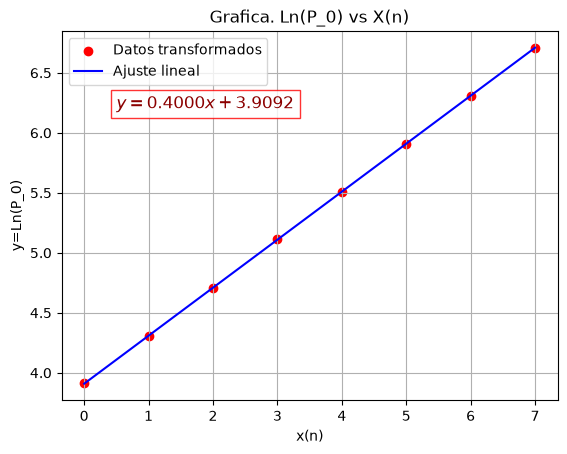

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

Y = np.log(Pn_puntos)
X = n_puntos
print(f'Cambio de variable y = \n{np.round(Y, 2)}')
print()
print(f'Cambio de variable x = \n{np.round(n_puntos, 2)}')

regresion_lineal_2 = linregress(X, Y)
ecuacion_recta= pendiente*X + intercepto
print(f'Ecuación de la recta: \n{ecuacion_recta}')
print()

pendiente = regresion_lineal_2.slope
intercepto = regresion_lineal_2.intercept
print(f'La pendiente m=ln(1+K) es igual a :{np.round(pendiente, 4)}')
print()
print(f'El intercepto b=ln(P_0) es igual a : {np.round(intercepto, 2)}')
print()

K = np.exp(pendiente) - 1
factor = 1 + K 
P_O = np.exp(intercepto)
print(f'El parametro de K es igual a:{np.round(K, 4)} ')
print()
print(f'el factor de K + 1 e igual a:{np.round(factor, 4)} ')
print()
print(f'intercepto de la recta es igual a: {np.round(P_O, 4)}')


plt.scatter(X, Y, color = 'red', label='Datos transformados' )
plt.plot(X,ecuacion_recta, color = 'blue', linestyle = '-', label='Ajuste lineal')
plt.title('Grafica. Ln(P_0) vs X(n)')
ecuacion_texto = f'$y = {pendiente:.4f}x + {intercepto:.4f}$'
plt.text(0.5, 6.2, ecuacion_texto, fontsize=12, color='darkred', bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))# plt.text(posicion_x, posicion_y, texto, opciones...)
plt.grid()
plt.xlabel('x(n)')
plt.ylabel('y=Ln(P_0)')
plt.legend()
plt.show()


Pregunta 3.

### 3. Modelo discreto del profesor.

Recordemos que

$$
P_{n+1}=(1+k)P_n.
$$

Como

$$
1+k\approx1.4895,
$$

obtenemos el modelo

$$
\boxed{P_{n+1}=1.4895P_n}.
$$

Como $P_0=50$, también podemos escribir la solución explícita:

$$
\boxed{P_n=50(1.4895)^n}.
$$

### 3. Modelo discreto de Juan sebastian.

Recordemos que

$$
P_{n+1}=(1+k)P_n.
$$

Como

$$
1+k\approx1.4919,
$$

obtenemos el modelo

$$
\boxed{P_{n+1}=1.4919P_n}.
$$

Como $P_0=50$, también podemos escribir la solución explícita:

$$
\boxed{P_n=49.8566(1.4919)^n}.
$$

Pregunta 4. solución profesor

se calcula los valores obtenidos con el modelo discreto su resultado es: 
[ 50.    74.48 110.93 165.23 246.11 366.58 546.03 813.31]

lista de arreglo de datos experimetales P_n:
[ 50  74 111 166 247 368 550 820]

la diferencia de cada valor de la poblacion con su valor experimental y el modelo obtenido es: 
[0.     0.475  0.0695 0.769  0.8884 1.4168 3.9743 6.6948]


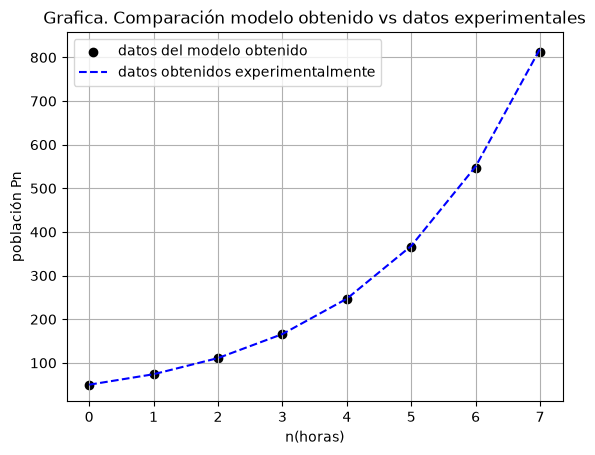

In [23]:
n =n_puntos
P_n = 50*(1.4895)** n

print(f'se calcula los valores obtenidos con el modelo discreto su resultado es: \n{np.round(P_n, 2)}')
print()
print(f'lista de arreglo de datos experimetales P_n:\n{Pn_puntos}')
print()
print(f'la diferencia de cada valor de la poblacion con su valor experimental y el modelo obtenido es: \n{np.round(np.absolute(P_n - Pn_puntos), 4) }')

plt.scatter(n, P_n, label = 'datos del modelo obtenido', color = 'black')
plt.plot(n_puntos, Pn_puntos, label = 'datos obtenidos experimentalmente', color = 'blue', linestyle = '--')
plt.title('Grafica. Comparación modelo obtenido vs datos experimentales')
plt.xlabel('n(horas)')
plt.ylabel('población Pn')
plt.legend()
plt.grid()
plt.show()

Pregunta 4. solución Sebastian 

se calcula los valores obtenidos con el modelo discreto su resultado es: 
[ 49.86  74.38 110.97 165.55 246.99 368.49 549.74 820.16]

lista de arreglo de datos experimetales P_n:
[ 50  74 111 166 247 368 550 820]

la diferencia de cada valor de la poblacion con su valor experimental y el modelo obtenido es: 
[0.1434 0.3811 0.0309 0.4452 0.0088 0.4862 0.2554 0.1639]


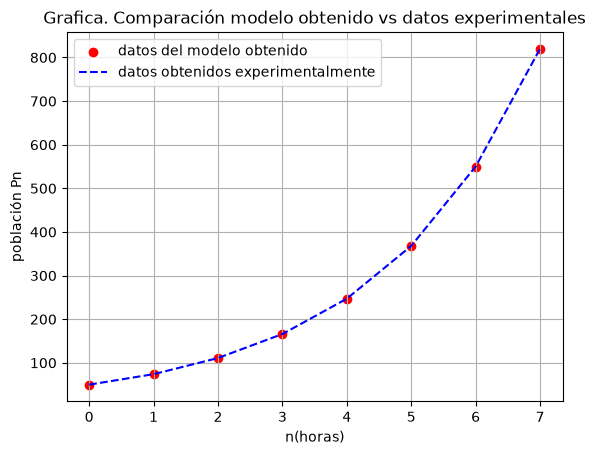

In [24]:
n = n_puntos
P_n = 49.8566*(1.4919)**n

print(f'se calcula los valores obtenidos con el modelo discreto su resultado es: \n{np.round(P_n, 2)}')
print()
print(f'lista de arreglo de datos experimetales P_n:\n{Pn_puntos}')
print()
print(f'la diferencia de cada valor de la poblacion con su valor experimental y el modelo obtenido es: \n{np.round(np.absolute(P_n - Pn_puntos), 4) }')

plt.scatter(n, P_n, label = 'datos del modelo obtenido', color = 'red')
plt.plot(n_puntos, Pn_puntos, label = 'datos obtenidos experimentalmente', color = 'blue', linestyle = '--')
plt.title('Grafica. Comparación modelo obtenido vs datos experimentales')
plt.xlabel('n(horas)')
plt.ylabel('población Pn')
plt.legend()
plt.grid()
plt.show()

Pregunta 5. solución profesor

In [25]:
n = 24
P_n = 50*(1.4895)**n
print(f'El número de bacterias estimadas después de 1 día es igual : \n{ np.round(P_n, 4)} ')


El número de bacterias estimadas después de 1 día es igual : 
711118.8413 


Pregunta 5. solución Sebastian

In [26]:
n = 24
P_n = 49.8566*(1.4919)**n
print(f'El número de bacterias estimadas después de 1 día es igual : \n{ np.round(P_n, 4)}')

El número de bacterias estimadas después de 1 día es igual : 
737014.0941


# Modelo Logistico discreto

El modelo logístico discreto permite describir el crecimiento de una población en intervalos de tiempo sucesivos, teniendo en cuenta que los recursos disponibles son limitados. A diferencia del modelo exponencial discreto, en el que la población puede crecer indefinidamente, el modelo logístico incorpora el efecto de la capacidad de carga del ambiente. Cuando la población es pequeña, dispone de suficientes recursos y puede crecer rápidamente; pero a medida que aumenta, la competencia por los recursos hace que su crecimiento disminuya.

Una forma sencilla de representar este comportamiento es mediante el modelo

$$
P_{n+1}=P_n+\kappa P_n\left(1-\frac{P_n}{K}\right),
$$

donde $P_n$ representa el tamaño de la población en el instante $n$, $\kappa$ es la tasa de crecimiento y $K$ es la capacidad de carga. El factor $\left(1-P_n/K\right)$ modifica el crecimiento dependiendo del tamaño de la población: cuando $P_n$ es pequeño, este factor es cercano a $1$ y el crecimiento se aproxima al exponencial; cuando $P_n$ se acerca a $K$, el crecimiento disminuye hasta hacerse prácticamente nulo. Así, el modelo permite representar una población que inicialmente crece rápidamente y que posteriormente tiende a estabilizarse alrededor de la capacidad de carga.



## Ejercicio: crecimiento de una población de peces


En un lago se introduce una pequeña población de peces. Durante los primeros meses, la población crece lentamente debido a que inicialmente hay pocos individuos. Posteriormente, al aumentar la población y mantenerse abundantes los recursos, el crecimiento se acelera. Finalmente, la disponibilidad limitada de alimento y espacio hace que el crecimiento vuelva a disminuir.

El número de peces se registra al final de cada mes:

| Tiempo $n$ (meses) | Población $P_n$ |
|---:|---:|
| 0 | 30 |
| 1 | 41 |
| 2 | 57 |
| 3 | 77 |
| 4 | 104 |
| 5 | 139 |
| 6 | 182 |
| 7 | 232 |
| 8 | 289 |
| 9 | 349 |
| 10 | 407 |
| 11 | 460 |
| 12 | 503 |
| 13 | 535 |
| 14 | 558 |
| 15 | 574 |
| 16 | 584 |
| 17 | 590 |
| 18 | 594 |
| 19 | 596 |
| 20 | 598 |

La gráfica de estos datos presenta una forma aproximadamente **sigmoidal**: el crecimiento es lento al comienzo, se acelera durante una etapa intermedia y finalmente se desacelera.

A diferencia del modelo exponencial, suponemos que el lago tiene una capacidad limitada para sostener peces. Esta capacidad máxima se denomina **capacidad de carga** y se representa por $K$.

Se propone el modelo logístico discreto

$$
P_{n+1}
=
P_n+rP_n\left(1-\frac{P_n}{K}\right),
$$

donde $r$ es la tasa de crecimiento y $K$ la capacidad de carga.

### Preguntas

1. Grafique los datos experimentales $(n,P_n)$ y describa el comportamiento observado.

2. Suponga que la capacidad de carga del lago es $K=600.$ Utilice los datos experimentales para estimar la tasa de crecimiento $r$.

3. Escriba el modelo logístico obtenido utilizando los valores estimados de $r$ y $K$.

4. Utilice el modelo para calcular la población durante los primeros 20 meses y compare gráficamente el modelo con los datos experimentales.

5. Utilice el modelo para estimar la población después de 25 meses.

6. Calcule la primera diferencia

    $$
    \Delta P_n=P_{n+1}-P_n
    $$

    y analice cómo cambia el crecimiento de la población. ¿En qué momento aproximadamente alcanza su máximo? ¿Qué ocurre cuando la población se aproxima a la capacidad de carga $K$?

7. Usando la teoria del punto fijo de sucesiones, determine por que el punto $P^* = K$ es estable.




Pregunta 1. solución 

lista de meses: 
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]

Lista de crecimiento de población de meses: 
[ 30  41  57  77 104 139 182 232 289 349 407 460 503 535 558 574 584 590
 594 596 598]


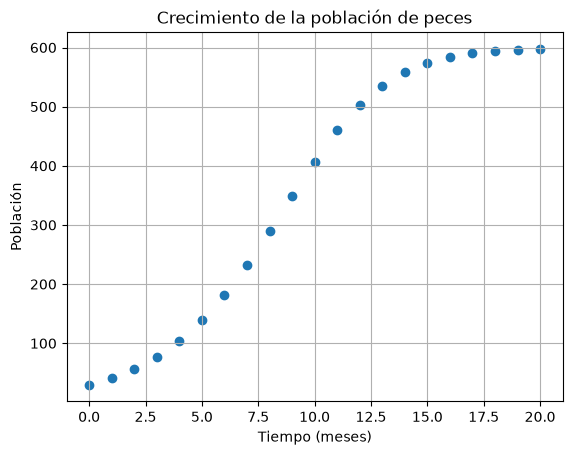

In [27]:
import numpy as np
import matplotlib.pyplot as plt

#Los datos presentan una forma aproximadamente sigmoidal. La población crece lentamente al comienzo, aumenta rápidamente durante la etapa intermedia y finalmente el crecimiento se hace más lento.

n_puntos = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
P_puntos = np.array([30, 41, 57, 77, 104, 139, 182, 232, 289, 349, 407, 460, 503, 535, 558, 574, 584, 590, 594, 596, 598])

print(f'lista de meses: \n{n_puntos}')
print()
print(f'Lista de crecimiento de población de meses: \n{P_puntos}')

plt.scatter(n_puntos, P_puntos)
plt.xlabel("Tiempo (meses)")
plt.ylabel("Población")
plt.title("Crecimiento de la población de peces")
plt.grid()
plt.show()

Pregunta 2. solución 

## Cambio de variable 


,$$P_{n+1} = P_n +  rP_n \left(1 - \frac{P_n}{K}\right)$$,

,$$P_{n+1} - P_n =  rP_n \left(1 - \frac{P_n}{K}\right)$$,

,$$\frac{P_{n+1} - P_n}{P_n} = r \left(1 - \frac{P_n}{K}\right)$$,

,$$\frac{P_{n+1} - P_n}{P_n} = r \cdot 1 - r \cdot \frac{P_n}{K}$$,

,$$\frac{P_{n+1} - P_n}{P_n} = r - \left(\frac{r}{K}\right) P_n$$,

,$$\underbrace{\frac{P_{n+1} - P_n}{P_n}}_{\text{Variable dependiente } y} = \underbrace{\left(-\frac{r}{K}\right)}_{\text{Pendiente } m} \cdot \underbrace{P_n}_{\text{Variable independiente }x} + \underbrace{r}_{\text{Intercepto } b}$$,




## Encontrar el parametro r

a. Como el despeje nos demostró que el intercepto de la recta es exactamente $r$, la fórmula directa es:$$r = b$$

b. Sabemos por la fórmula de la pendiente que:$$m = -\frac{r}{K}$$ Se despeja $r$ pasando la capacidad de carga $K$ a multiplicar, queda:$$r = -m \cdot K$$

Cambio relativo de una mes y el siguiente: 
[11 16 20 27 35 43 50 57 60 58 53 43 32 23 16 10  6  4  2  2]

Población actual en cada instante: 
[ 30  41  57  77 104 139 182 232 289 349 407 460 503 535 558 574 584 590
 594 596]

Transformación de datos para la variable Y: 
[0.3667 0.3902 0.3509 0.3506 0.3365 0.3094 0.2747 0.2457 0.2076 0.1662
 0.1302 0.0935 0.0636 0.043  0.0287 0.0174 0.0103 0.0068 0.0034 0.0034]

Transformacion de datos para la variable X: 
[ 30  41  57  77 104 139 182 232 289 349 407 460 503 535 558 574 584 590
 594 596]
La pendiente obtenida es: 
-0.0007

El intercepto obtenido es: 
0.3999

La tasa de creciemiento obtenida por el intercepto: 
3.90915

La tasa de crecieminto obtenida por la pendiente es igual: 
0.39982


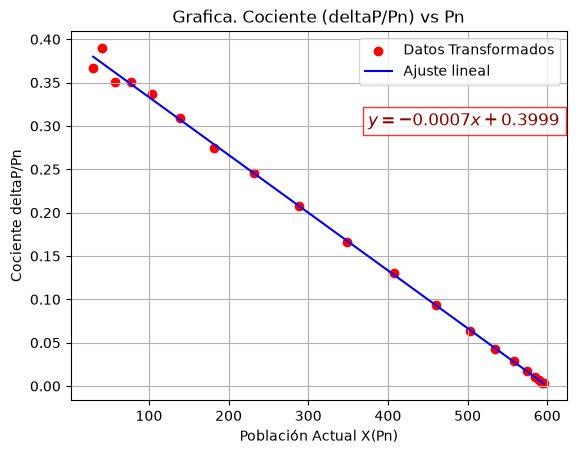

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

delta_P = P_puntos[1:] - P_puntos[:-1]
P_actual = P_puntos[:-1]
print(f'Cambio relativo de una mes y el siguiente: \n{np.round(delta_P, 2)}')
print()
print(f'Población actual en cada instante: \n{np.round(P_actual, 2)}')
print()

# Transformación de datos
Y = delta_P / P_actual
X = P_actual

print(f'Transformación de datos para la variable Y: \n{np.round(Y, 4)}')
print()
print(f'Transformacion de datos para la variable X: \n{np.round(X)}')

# Regresión lineal
regresion_lineal = linregress(X, Y)
Pendiente = regresion_lineal.slope
Intercepto = regresion_lineal.intercept
Ecuacion_recta = Pendiente*X + Intercepto

print(f'La pendiente obtenida es: \n{np.round(Pendiente, 4)}')
print()
print(f'El intercepto obtenido es: \n{np.round(Intercepto, 4)}')
print()

# a. obtenemos el parametro r (tasa de creciemiento), sabemos que b = r
Tasa_crecimiento_a = intercepto
print(f'La tasa de creciemiento obtenida por el intercepto: \n{np.round(Tasa_crecimiento_a, 5)}')
print()

# b. la pendiente m = -(r/k) despejamos -m.k = r
K = 600 #capacidad de carga
Tasa_crecimiento_b = -(Pendiente*K)

print(f'La tasa de crecieminto obtenida por la pendiente es igual: \n{np.round(Tasa_crecimiento_b, 5)}')

plt.scatter(X, Y, color = 'red', label = 'Datos Transformados')
plt.plot(X, Ecuacion_recta, color='blue', linestyle='-', label='Ajuste lineal')
ecuacion_texto = f'$y = {Pendiente:.4f}x + {Intercepto:.4f}$'
plt.text(375, 0.30, ecuacion_texto, fontsize=12, color='darkred', bbox=dict(facecolor='white', alpha=0.8, edgecolor='red'))# plt.text(posicion_x, posicion_y, texto, opciones...)
plt.title('Grafica. Cociente (deltaP/Pn) vs Pn')
plt.xlabel('Población Actual X(Pn)')
plt.ylabel('Cociente deltaP/Pn')
plt.legend()
plt.grid()

Pregunta 3. solución

## Modelo logistico Obtenido

$$
r=0.3999,
\qquad
K=600,
\qquad
P_0=30,
$$

obtenemos

$$
\boxed{
P_{n+1}
=
P_n+0.4P_n\left(1-\frac{P_n}{600}\right),
\qquad P_0=30.
}
$$

Este es el modelo que utilizaremos para realizar las predicciones.

Pregunta 4. solución

Mes 1: 41.4 peces
Mes 2: 56.81 peces
Mes 3: 77.38 peces
Mes 4: 104.33 peces
Mes 5: 138.8 peces
Mes 6: 181.46 peces
Mes 7: 232.08 peces
Mes 8: 288.99 peces
Mes 9: 348.9 peces
Mes 10: 407.29 peces
Mes 11: 459.6 peces
Mes 12: 502.61 peces
Mes 13: 535.23 peces
Mes 14: 558.34 peces
Mes 15: 573.84 peces
Mes 16: 583.85 peces
Mes 17: 590.13 peces
Mes 18: 594.01 peces
Mes 19: 596.38 peces
Mes 20: 597.82 peces

Predicciones de la población de peces con el modelo obtenido: 
[ 30.    41.4   56.81  77.38 104.33 138.8  181.46 232.08 288.99 348.9
 407.29 459.6  502.61 535.23 558.34 573.84 583.85 590.13 594.01 596.38
 597.82]


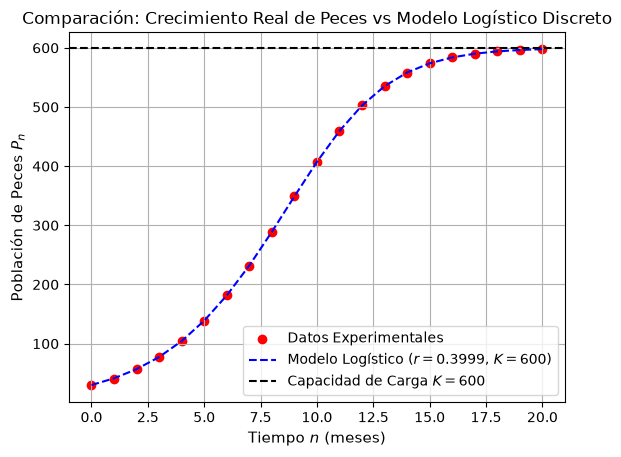

In [29]:
r = 0.3999 # Tasa de Crecieminto
K = 600 # Capacidad de carga

P_n = np.zeros(21)
P_n[0] = 30

for n in range(20):
    P_n[n+1] = (  P_n[n]  + r * P_n[n] * (1 - P_n[n] / K)   )
    print(f'Mes {n+1}: {np.round(P_n[n+1], 2)} peces')

print()
print(f'Predicciones de la población de peces con el modelo obtenido: \n{np.round(P_n, 2)}')

plt.scatter(n_puntos, P_puntos, color = 'red', label = 'Datos Experimentales')
plt.plot(n_puntos, P_n, color='blue', linestyle='--', label=f'Modelo Logístico ($r={r:.4f}$, $K={K}$)')
plt.axhline(y=K, color='black', linestyle='--', label=f'Capacidad de Carga $K = {K}$')
plt.title('Comparación: Crecimiento Real de Peces vs Modelo Logístico Discreto')
plt.xlabel('Tiempo $n$ (meses)', fontsize=11)
plt.ylabel('Población de Peces $P_n$', fontsize=11)
plt.legend()
plt.grid()
plt.show()


Pregunta 5. solución

In [30]:
import numpy as np

r = 0.3999
K = 600

# se crea un arreglo de tamaño 26 (desde el mes 0 hasta el mes 25)
P_n = np.zeros(26)
P_n[0] = 30  # Población inicial en el mes 0

# El bucle corre 25 veces para calcular desde n=0 hasta n=24, llegando al mes 25
for n in range(25):
    P_n[n+1] = P_n[n] + r * P_n[n] * (1 - P_n[n] / K)

# El último valor del arreglo (el índice 25) es la población en el mes 25
print(f'Población estimada en el mes 25: {P_n[25]:.2f}')

Población estimada en el mes 25: 599.83


Pregunta 6. solución

Se calcula la diferencia:

$$\Delta P_n = P_{n+1} - P_n$$

$\Delta P_n$ representa cuántos peces nuevos nacieron (o se sumaron netamente) de un mes al siguiente.

Del mes 0 al 1:   $41 - 30 = 11$ peces nuevos
<br>
Del mes 1 al 2:   $57 - 41 = 16$ peces nuevos
<br>
Del mes 2 al 3:   $77 - 57 = 20$ peces nuevos
<br>
Del mes 3 al 4:   $104 - 77 = 27$ peces nuevos
<br>
Del mes 4 al 5:   $139 - 104 = 35$ peces nuevos
<br>
Del mes 5 al 6:   $182 - 139 = 43$ peces nuevos
<br>
Del mes 6 al 7:   $232 - 182 = 50$ peces nuevos
<br>
Del mes 7 al 8:   $289 - 232 = 57$ peces nuevos
<br>
Del mes 8 al 9:   $349 - 289 = 60$ peces nuevos (Pico Maximo)
<br>
Del mes 9 al 10:  $407 - 349 = 58$ peces nuevos
<br>
Del mes 10 al 11: $460 - 407 = 53$ peces nuevos
<br>

(Y a partir de ahí, el número de peces nuevos cada mes empieza a disminuir: 43, 33, 23, 16, 10, 6, 4, 2, 2... hasta llegar a casi 0).

en el mes 8 hay 289 peces y en el mes 9 hay 349 peces. Es justo ahí, al cruzar los 300 peces (alrededor del mes 8 o 9), donde la población experimenta su velocidad de crecimiento más alta.

el comportamiento final del sistema cuando llega al limite de la capacidad de carga (k=600):

$$\Delta P_n = P_{n+1} - P_n$$

viendo en detalle:

,$$\left(1 - \frac{P_n}{K}\right)$$,

si la población es pequeña (ej: $P_n = 30$), la fracción es $\frac{30}{600} = 0.05$. Al restarla de 1 queda $1 - 0.05 = 0.95$ (un número muy cercano a 1, por lo que el crecimiento casi no se frena).

A medida que la población crece (ej: $P_n = 500$), la fracción sube: $\frac{500}{600} = 0.83$. Al restarla de 1 queda $1 - 0.83 = 0.17$ (el factor de crecimiento se vuelve diminuto porque hay mucha competencia).

Cuando la población alcanza el límite total ($P_n = 600$), la fracción se vuelve 1: $\frac{600}{600} = 1$. Al hacer la resta queda 0.

$$\Delta P_n = r P_n \cdot (0) = 0$$

$$P_{n+1} - P_n = 0 \implies P_{n+1} = P_n$$

la población del mes siguiente es exactamente igual a la población del mes actual. Ya no hay aumento. Lo que ocurre es un estado de equilibrio estático o de saturación:

Se acabaron los recursos: Ya no hay suficiente espacio físico en el estanque, el oxígeno se reduce y la comida se vuelve insuficiente para más animales.

Muerte vs. Nacimientos: La tasa de nacimientos se desacelera tanto que empata exactamente con la tasa de mortalidad natural.

El aplanamiento de la curva: Gráficamente, la curva deja de subir en forma de "S" (sigmoide) y se vuelve una línea horizontal completamente plana pegada al techo de $K = 600$.


Diferencias delta de p cambio relativo de un mes y el siguiente:
[11 16 20 27 35 43 50 57 60 58 53 43 32 23 16 10  6  4  2  2]


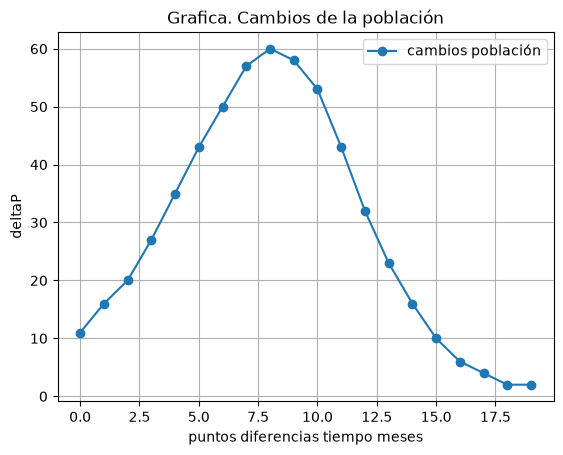

In [31]:
delta_P = P_puntos[1:] - P_puntos[:-1]
n_puntos_diferencias = range(len( delta_P ))

print(f'Diferencias delta de p cambio relativo de un mes y el siguiente:\n{delta_P}')

plt.plot(n_puntos_diferencias, delta_P, marker = 'o', linestyle = '-', label ='cambios población')
plt.title('Grafica. Cambios de la población')
plt.xlabel('puntos diferencias tiempo meses')
plt.ylabel('deltaP')
plt.legend()
plt.grid()
plt.show()

Pregunta 7. solución

## estabiidad del $P^*$ = $K$

El modelo logístico discreto está dado por la relación de recurrencia:$$P_{n+1} = P_n + r P_n \left(1 - \frac{P_n}{K}\right)$$

Definimos la función de iteración $f(P)$ tal que $P_{n+1} = f(P_n)$:$$f(P) = P + r P \left(1 - \frac{P}{K}\right) = P + r P - \frac{r}{K} P^2$$

Verificación del Punto Fijo $P^* = K$ Un punto $P^*$ es un punto fijo si satisface $f(P^*) = P^*$:$$f(K) = K + r(K) \left(1 - \frac{K}{K}\right) = K + r K (1 - 1) = K$$

$P^*$ es asintóticamente estable (o un atractor):

$$\vert{}f'(P^*)\vert{} < 1$$

Derivamos $f(P)$ con respecto a $P$: 

,$$f'(P) = \frac{d}{dP} \left[ P + r P - \frac{r}{K} P^2 \right]$$,

$$f'(P) = 1 + r - \frac{2r}{K} P$$

Sustituimos $P = K$ en la derivada:

,$$f'(K) = 1 + r - \frac{2r}{K} (K)$$,

,$$f'(K) = 1 + r - 2r$$,

$$f'(K) = 1 - r$$

Aplicando el criterio de estabilidad $\vert{}f'(K)\vert{} < 1$:

$$\vert{}1 - r\vert{} < 1$$

Esto equivale a la desigualdad doble:

$$-1 < 1 - r < 1$$

Restamos $1$ en todos los miembros:

$$-2 < -r < 0$$

Multiplicamos por $-1$ (invirtiendo el sentido de las desigualdades):

$$0 < r < 2$$

conclusión:

El punto fijo $P^* = K$ es asintóticamente estable para cualquier tasa de crecimiento que cumpla $0 < r < 2$.

Dado que en tu modelo se estimó $r \approx 0.3999$ (o $0.40$), el valor está dentro del rango $(0, 2)$:

$$\vert{}f'(K)\vert{} = \vert{}1 - 0.3999\vert{} = \vert{}0.6001\vert{} = 0.6001 < 1$$

## si el punto fijo es igual a 0:

Usando la función de iteración del modelo logístico discreto:

$$f(P) = P + r P \left(1 - \frac{P}{K}\right)$$

Evaluamos en $P^* = 0$:

$$f(0) = 0 + r(0) \left(1 - \frac{0}{K}\right) = 0$$

Por lo tanto, $P^* = 0$ cumple con $f(P^*) = P^*$, confirmando que es un punto fijo.

Evaluación de la derivada en $P^* = 0$

La derivada de la función de iteración $f(P)$ es:

$$f'(P) = 1 + r - \frac{2r}{K} P$$

Sustituimos $P^* = 0$ en la derivada:

$$f'(0) = 1 + r - \frac{2r}{K}(0) = 1 + r$$

Aplicación del criterio de estabilidad $\vert{}f'(P^*)\vert{} < 1$

Conclusión sobre la estabilidad de $P^* = 0$

Inestabilidad: Dado que la tasa de crecimiento biológico de la población es positiva ($r > 0$, en nuestro caso $r \approx 0.40$), la derivada resulta:

$$f'(0) = 1 + 0.40 = 1.40 > 1$$

Como $\vert{}f'(0)\vert{} > 1$, el punto fijo $P^* = 0$ es inestable (un repulsor). Esto significa que si se introduce una cantidad pequeña de peces en el estanque ($P_0 > 0$), la población no se extinguirá ni permanecerá en cero, sino que crecerá alejándose de cero y dirigiéndose hacia la capacidad de carga estable $P^* = K = 600$.




